In [21]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 11.3 MB/s  0:00:000.6 MB/s eta 0:00:0101
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 15.9 MB/s  0:00:00 18.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 12.5 MB/s  0:00:00a 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install -q torch

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install --upgrade statsmodels anndata

Note: you may need to restart the kernel to use updated packages.


In [4]:
import sys; print(sys.executable)

/Users/nethanramachandran/miniconda3/envs/concert-toy/bin/python


In [5]:
import numpy as np
import pandas as pd
import torch
import statsmodels.api as sm
import statsmodels.formula.api as smf
import anndata as ad

In [6]:
import random
rng = np.random.default_rng(seed=42)
    


In [10]:
# How do we incorporate this model 
# We have the 18 different conditions, 
# We have a parameter generated for every single different combination
# 122 genes x 3 different conditions x 6 different KO's -> 2196 different parameters!

# How can we incorporate the gene embeddings aka a different way to do so.

In [11]:
## Redid Model

In [12]:
EXCLUDE_TARGET_GENES = True                  # drop the 6 knocked-down genes from the gene columns
de = ad.read_h5ad("DE_stats_model_subset.h5ad")

conditions = ["Rest", "Stim8hr", "Stim48hr"]

# This step builds the list of the 6 knockouts, in a fixed order, from the 18-row table. Here’s what the table looks like at each stage.
targets = (de.obs.drop_duplicates("target_contrast")
             .sort_values("model_target_order")["target_contrast_gene_name"].tolist())

# target_ids is used for matching. 
# The file identifies rows and gene columns by Ensembl ID, so the loop uses target_ids.index(tid) to find a row’s knockout position p, and gene_mask uses the IDs to find the knocked-down genes’ columns.
# Knocked out genes
target_ids = (de.obs.drop_duplicates("target_contrast")
                .sort_values("model_target_order")["target_contrast"].tolist())

# removed the knocked-down genes' columns -> Keep ever gene column whose ID is not in target_ids. 
# Drops the 6 knocked-down genes and keeps 122. Becacuse we are not measuring the activity of the knocked down genes
# We are trying to understand the downstream effect of the non-knocked out genes
gene_mask = ~de.var_names.isin(target_ids) if EXCLUDE_TARGET_GENES else np.ones(de.n_vars, bool)
genes = de.var["gene_name"][gene_mask].tolist()


# Stores the sizes of the knockouts, conditions, and genes that have not been knocked out
P, C, G = len(targets), len(conditions), len(genes)

#Empty 3D arrays
# Each array is a stack of 6 sheets, one per knockout, each sheet has 3 rows(conditionns) and 122 columns)

# y is the log-fold change values
# SE will hold the standard errors -> Standard sees how uncertain the estimate is, or how much it would wobble if you reran the experiment
Y  = np.full((P, C, G), np.nan)
SE = np.full((P, C, G), np.nan)


# Pulls out the two data tables
# lfc_all is the log fold change table stored in the file 18 (knockouts x conditions) x 128 genes
# se_all is the matching table of standard errors
lfc_all = np.asarray(de.layers["log_fc"])
se_all  = np.asarray(de.layers["lfcSE"])

#Copies each of the files 18 rows into Y[p,c and SE[p,c] slot. The new part is the 3 lines after it, which turn standard errors into 
# weights -> weight allows the model to not treat every log_fc as equally trustworthy.

for row, (tid, cond) in enumerate(zip(de.obs["target_contrast"], de.obs["culture_condition"])):
    p, c = target_ids.index(tid), conditions.index(cond)
    # lfc_all[0, gene_mask] takes row 0’s log_fc values for the 122 kept genes: [0.08, 0.21, …] (DPM1, SCYL3, …).
    # These are stored in Y[0, 0], the KDM1A / Rest mailbox.
    Y[p, c]  = lfc_all[row, gene_mask]
    SE[p, c] = se_all[row, gene_mask]

# Weighing by 1/variance which is 1/(SE^2) -> converts every value into the variance weight
# the smaller the SE the more precide it is, the greater it is the less precise, so dividing by one over the value makes it more inverse.
W = 1.0 / SE**2

# These two lines are a cleanup step: they find any missing or broken values and make sure they can’t break the model. 
# On your file they change nothing, since there’s no missing data, but they protect you on messier data.

W[~np.isfinite(W) | np.isnan(Y)] = 0.0      # missing values get zero weight
Y = np.nan_to_num(Y)

print(f"knockouts P={P}, conditions C={C}, genes G={G}  →  β has P×G = {P*G} numbers")
print("targets:", targets)
print("NaNs in log_fc:", np.isnan(lfc_all).sum(), "  NaNs in lfcSE:", np.isnan(se_all).sum())

knockouts P=6, conditions C=3, genes G=122  →  β has P×G = 732 numbers
targets: ['KDM1A', 'CREBBP', 'KMT2E', 'FBXL3', 'MED24', 'CSDE1']
NaNs in log_fc: 0   NaNs in lfcSE: 0


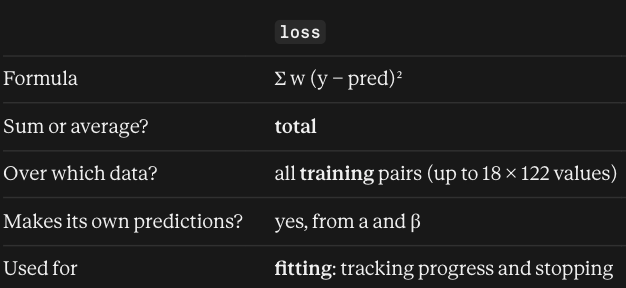

In [13]:
# Y, W: P × C × G (6 × 3 × 122)
# a: C (3), one gain per condition
# beta: P × G (6 × 122), one fingerprint per knockout
# train: P × C (6 × 3), True/False per pair -> tells me which of the 18 (KO, condition) pairs the model is allowed to learn from 

# Just computes how wrong the model is


# Read from the inside out:

# Y - pred: the miss for every entry
# ** 2: squared
# * W: weighted by trust (1/SE²)
# * train[:, :, None]: multiplied by 1 for training pairs and 0 for hidden ones, so hidden pairs don’t count
# np.sum(...): add everything into one number
def loss(Y, W, a, beta, train):
    # L = Σ w (y − a_c β)²   over training pairs only
    # None inserts a size-1 axis, and numpy then repeats the array along that axis as needed
    # a -> 1:3:1 the same 3 gains in every knockout and gene
    # beta -> the same fingerprint in every condition
    # the same True/False for every gene of a pai
    pred = a[None, :, None] * beta[:, None, :]           # P × C × G
    # Weighted squared errors between observed log_fc and the model's predictions, over the training pairs only
    return np.sum(train[:, :, None] * W * (Y - pred) ** 2)

## Step 1: Update Beta - Computes every knockout's fingerprint, given the current gains

The formula answers: “Given the gains, what’s the best single Rest-level effect β for this knockout × gene?”

overall the model says log_fc = a(change due to condition) x B(change due to perturbation)
B = y/c -> Guess
Then apply the weighted average
The formula below is a weighted average of these guesses. You can rewrite it the multiplication of the weights 

![Screenshot 2026-11-17 at 4.31.10 PM.png](attachment:ec045f2e-a0b9-4905-9b99-79e286fe81ca.png)
![Screenshot 2026-11-17 at 4.41.23 PM.png](attachment:5f2dd16c-c41e-4bae-9bc0-b8968795dd23.png)
![Screenshot 2026-11-17 at 4.58.08 PM.png](attachment:2dd6e4d2-9f91-477a-b52c-fb6a290d1d23.png)

![image.png](attachment:4f2dc905-711a-4630-8cc7-8b02dc6710c1.png)

Essentially it is over all conditions, you multiply the (weights x value)/(over sum of all the weights)
Dividing makes the weights act as a fractions of the total, so the result always falls between the smallest and largest value


“Fixing a” just means treating the current gains as known numbers while computing β. update_beta receives a as an input, uses it in the formula, and never changes it.

Overall you are multiplying the weights*the observed calculated B/ dividing over the total gain -> to get the Beta averaged from all the conditions. 

In [14]:
def update_beta(Y, W, a, train):
    # Step 1 — fix a, solve for β:  β = Σ_c w a y / Σ_c w a²
    P, C, G = Y.shape                  # 6 knockouts, 3 conditions, 122 genes
    beta = np.zeros((P, G))            # one β per knockout × gene, starts at 0

    for p in range(P):                 # each knockout
        for g in range(G):             # each gene
            num = 0.0                  # running total for Σ_c w a y
            den = 0.0                  # running total for Σ_c w a²
            for c in range(C):         # each condition
                if train[p, c]:        # skip hidden pairs
                    num += W[p, c, g] * a[c] * Y[p, c, g]
                    den += W[p, c, g] * a[c] ** 2
            if den > 0:                # only divide if there was usable data
                beta[p, g] = num / den # otherwise β stays 0
    return beta

update_a is the mirror image of update_beta. Now the fingerprints β are fixed (known), and it computes the best gain for each stimulated condition.
It answers: “Across everything measured in condition c, how much bigger (or smaller) is what we observed than the Rest fingerprint predicts?”

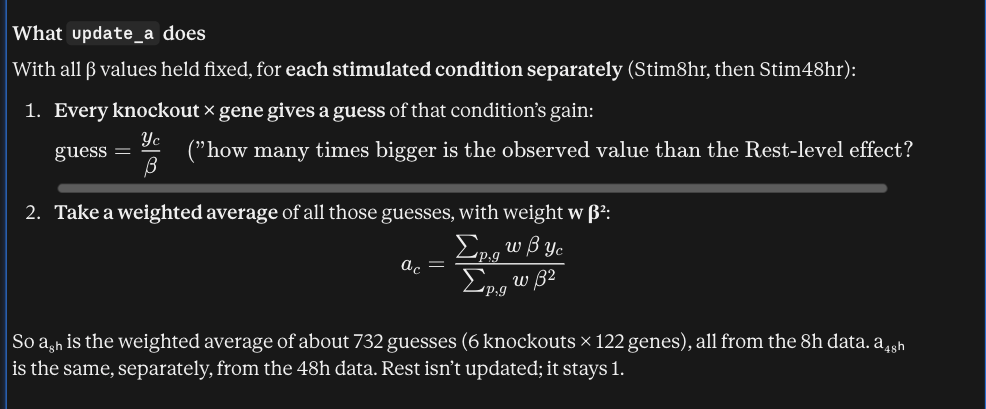
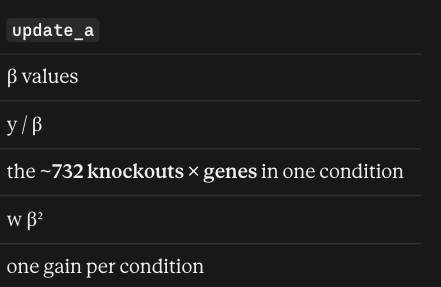

In [15]:
def update_a_loop(Y, W, beta, train):
    # Step 2 — fix β, solve for each a_c:  a_c = Σ_{p,g} w β y / Σ_{p,g} w β²   (Rest stays 1)
    P, C, G = Y.shape                  # 6 knockouts, 3 conditions, 122 genes
    a = np.ones(C)                     # [1, 1, 1]; slot 0 (Rest) is never changed

    for c in range(1, C):              # each stimulated condition: 1 = Stim8hr, 2 = Stim48hr
        num = 0.0                      # running total for Σ w β y
        den = 0.0                      # running total for Σ w β²
        for p in range(P):             # each knockout
            if train[p, c]:            # skip hidden pairs
                for g in range(G):     # each gene
                    num += W[p, c, g] * beta[p, g] * Y[p, c, g]
                    den += W[p, c, g] * beta[p, g] ** 2
        a[c] = num / den if den > 0 else 1.0   # no usable data → leave the gain at 1
    return a

## Model_A
1.) Δ = β_p,g

2.) a knockout has the same effect in every condition

3.) Parameters:	732 β

4.) β is weighted average of the conditions

5.) Fitting	Step 1 once, with a = [1, 1, 1]


In [16]:
def fit_model_A(Y, W, train):
    # Model A = gain model with a = [1, 1, 1]
    a = np.ones(Y.shape[1])
    return a, update_beta(Y, W, a, train)

## Gain Model

1.) Δ = a꜀ · β_p,g

2.) the effect has the same pattern, but each condition scales it up or down

3.) 732 β + 2 gains (a₈ₕ, a₄₈ₕ) = 734

4.) weighted average of the conditions after undoing each gain

5.) Fitting: alternate Step 2 and Step 1 until converged (46 rounds)


## Parameters:
Y, W: the data and weights.

train: which pairs to learn from.

n_iter=100: a safety limit of at most 100 rounds.

tol=1e-10: “close enough”: stop when the loss improves by less than 0.00000001%.

verbose: print progress or not.


## Initial with every a = 1:

1. It’s the baseline model (Model A).
With every a = 1:

each guess y꜀ / a꜀ is just y꜀, the observed value itself

### β becomes the plain weighted average of the three conditions

the prediction a꜀ × β = β is the same in every condition

That’s the simplest assumption: “a knockout has the same effect no matter the condition.” It’s the model the gain model gets compared against. If the gains can’t beat it on held-out pairs, they aren’t adding anything. On your data they didn’t: Model A was equal or slightly better.

In [17]:
def fit_gain_model(Y, W, train, n_iter=100, tol=1e-10, verbose=False):
    a = np.ones(Y.shape[1])                      # start at Model A - size will be three conditions

    # Step #1: Find the initial fingerprints (Beta values) in Beta with the initial alpha values of 1
    beta = update_beta(Y, W, a, train)
    # Measures the initial loss from that list
    history = [loss(Y, W, a, beta, train)]
    # Train over 100 iterations
    for it in range(n_iter):
        # update the gains by keeping Beta constant
        a = update_a_loop(Y, W, beta, train)          # step 2
        beta = update_beta(Y, W, a, train)       # step 1
        history.append(loss(Y, W, a, beta, train)) # Find the loss again
        if verbose and (it < 3 or (it + 1) % 10 == 0):
            print(f"round {it+1:2d}  a = {np.round(a, 4)}  loss = {history[-1]:.2f}")
        if abs(history[-2] - history[-1]) < tol * history[-2]:   # stop when loss stops changing
            break
    if verbose:
        print(f"stopped after {it+1} rounds")
    return a, beta, history
    

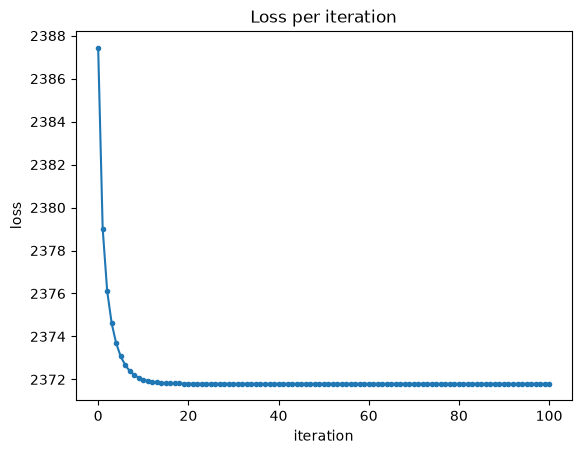

In [22]:
%matplotlib inline
import matplotlib.pyplot as plt

train_all = np.ones((P, C), bool)                                    # use all 18 pairs
a_hat, beta_hat, history = fit_gain_model(Y, W, train_all, n_iter=100, tol=0)

plt.plot(history, marker="o", markersize=3)
plt.xlabel("iteration")
plt.ylabel("loss")
plt.title("Loss per iteration")
plt.show()

In [ ]:
# Weighted mean square error: average squared miss between the true values y and the predictions yhat.

In [18]:
def wmse(y, yhat, w):
    return np.sum(w * (y - yhat) ** 2) / np.sum(w)

rows = []
# Loop over all 18 pairs
for p in range(P):
    for c in range(C):
        # Hide one pair -> trains on the other two pairs
        train = np.ones((P, C), bool); train[p, c] = False     # hide this pair

        # all learned parameters from both model types
        aA, bA = fit_model_A(Y, W, train)
        aG, bG, _ = fit_gain_model(Y, W, train)

        # Get the hidden pair's real values
        y_true = Y[p, c]; w = W[p, c]
        # Using the provided parameters, predict the gain of accuracy
        pred_A = aA[c] * bA[p]          # Model A: same effect as other conditions
        pred_G = aG[c] * bG[p]          # gain model: a_c × β_p
        rows.append({
            "knockout": targets[p], "condition": conditions[c],
            "a_c used": round(aG[c], 3),
            "wMSE A": wmse(y_true, pred_A, w), "wMSE gain": wmse(y_true, pred_G, w),
            "r A": np.corrcoef(y_true, pred_A)[0, 1], "r gain": np.corrcoef(y_true, pred_G)[0, 1],
        })

heldout = pd.DataFrame(rows)
heldout["gain better?"] = heldout["wMSE gain"] < heldout["wMSE A"]
print(heldout.round(3).to_string(index=False))

print("\nAverages over 18 held-out pairs:")
print(heldout[["wMSE A", "wMSE gain", "r A", "r gain"]].mean().round(4).to_string())
print(f"Gain model better on {heldout['gain better?'].sum()} / {len(heldout)} pairs")

knockout condition  a_c used  wMSE A  wMSE gain    r A  r gain  gain better?
   KDM1A      Rest     1.000   0.035      0.034  0.550   0.548          True
   KDM1A   Stim8hr     1.286   0.027      0.034  0.723   0.728         False
   KDM1A  Stim48hr     0.952   0.034      0.032  0.709   0.719          True
  CREBBP      Rest     1.000   0.021      0.020  0.557   0.560          True
  CREBBP   Stim8hr     1.166   0.014      0.014  0.774   0.771         False
  CREBBP  Stim48hr     1.149   0.018      0.019  0.691   0.692         False
   KMT2E      Rest     1.000   0.034      0.031  0.104   0.100          True
   KMT2E   Stim8hr     1.251   0.039      0.047 -0.147  -0.151         False
   KMT2E  Stim48hr     1.041   0.042      0.041 -0.000  -0.010          True
   FBXL3      Rest     1.000   0.019      0.018  0.382   0.385          True
   FBXL3   Stim8hr     1.238   0.018      0.021  0.496   0.496         False
   FBXL3  Stim48hr     1.072   0.019      0.018  0.547   0.549          True